## Outliers  >> Outliers are extreme values

In [3]:
import pandas as pd 
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

import warnings
warnings.filterwarnings("ignore")

In [4]:
salary = [11, 40, 45, 68, 65, 68, 78, 90, 57, 74, 91, 92, 88, 68, 57, 48, 99, 101, 68, 77, 110, 140]


In [5]:
salary

[11,
 40,
 45,
 68,
 65,
 68,
 78,
 90,
 57,
 74,
 91,
 92,
 88,
 68,
 57,
 48,
 99,
 101,
 68,
 77,
 110,
 140]

## five point summary
### minimum value 25th, 50th ,75th,100th percentile

In [37]:
np.quantile(salary,[0,0.25,0.50,0.75,1])

array([ 11.  ,  59.  ,  71.  ,  90.75, 140.  ])

In [8]:
df = pd.DataFrame(salary,columns = ['salary'])

In [9]:
df

,salary
0,11
1,40
2,45
3,68
4,65
5,68
6,78
7,90
8,57
9,74


In [11]:
df.describe()

,salary
count,22.000000
mean,74.318182
std,27.201867
min,11.000000
25%,59.000000
50%,71.000000
75%,90.750000
max,140.000000


<function matplotlib.pyplot.show(close=None, block=None)>

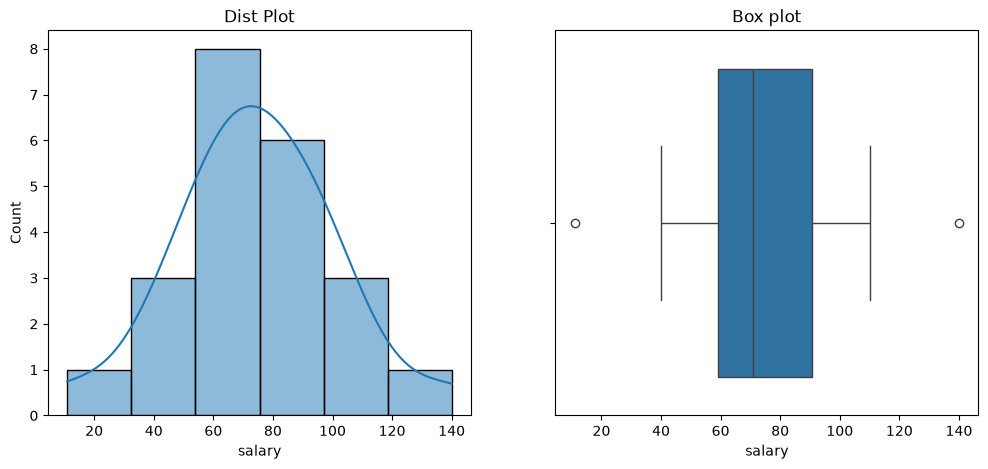

In [15]:
# to check outliers >> distplot,boxplot

plt.figure(figsize = (12,5)) # set the size of graph
plt.subplot(1,2,1) # give space to plot two graph in one figure 1=rows,2=columns,1 = first graph
sns.histplot(df['salary'],kde = True) # kde show smooth curve
plt.title("Dist Plot")


plt.subplot(1,2,2)
sns.boxplot(data=df,x = 'salary')
plt.title("Box plot")
plt.show

In [16]:
# here the distribution is not skewed as the outliers are present on both side
# in box plot, we see the outliers 
# dropping the outliers 
# capping the outlier
# replace with mean and median


#### dropping the outliers 

In [20]:
Q1 = df['salary'].quantile(0.25) # 25% of data
Q3 = df['salary'].quantile(0.75) # 75% of data

IQR = Q3 -Q1 # 50% of data

lower_fence = Q1-1.5*IQR 
upper_fence = Q3+1.5*IQR

In [23]:
df_filtered = df[(df.salary >= lower_fence) & (df.salary <= upper_fence)]

In [24]:
df.shape

(22, 1)

<function matplotlib.pyplot.show(close=None, block=None)>

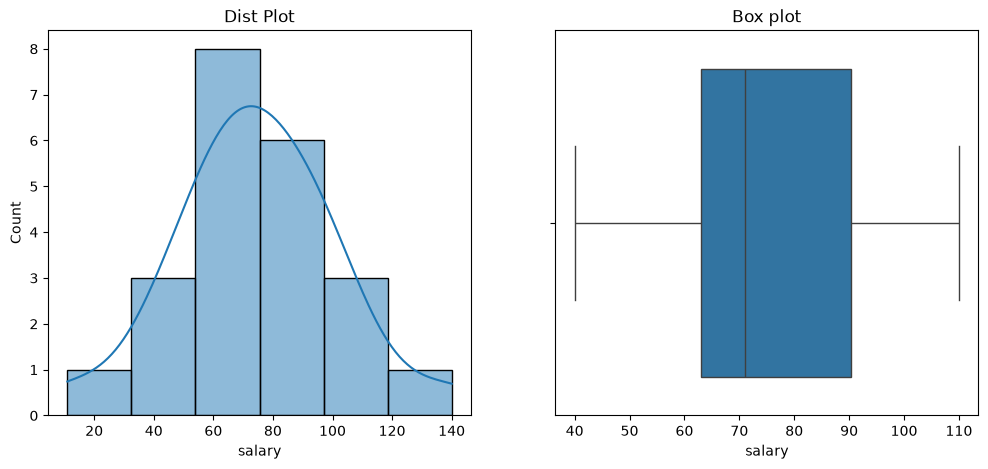

In [25]:
# here there are not any outliers

plt.figure(figsize = (12,5))
plt.subplot(1,2,1)
sns.histplot(df['salary'],kde = True)
plt.title("Dist Plot")


plt.subplot(1,2,2)
sns.boxplot(data=df_filtered,x = 'salary')
plt.title("Box plot")
plt.show

## imputation with mean 

In [29]:

df['salary_imputed_mean'] = np.where((df.salary >= upper_fence) | (df.salary <= lower_fence), df['salary'].mean(),df['salary'])

In [30]:
df['salary_imputed_mean']

0      74.318182
1      40.000000
2      45.000000
3      68.000000
4      65.000000
5      68.000000
6      78.000000
7      90.000000
8      57.000000
9      74.000000
10     91.000000
11     92.000000
12     88.000000
13     68.000000
14     57.000000
15     48.000000
16     99.000000
17    101.000000
18     68.000000
19     77.000000
20    110.000000
21     74.318182
Name: salary_imputed_mean, dtype: float64

<function matplotlib.pyplot.show(close=None, block=None)>

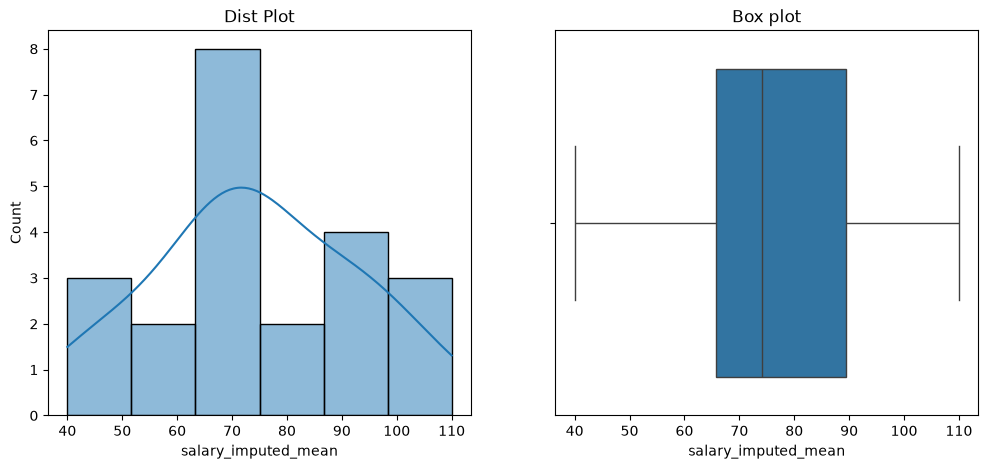

In [31]:
# imputation with mean

plt.figure(figsize = (12,5))
plt.subplot(1,2,1)
sns.histplot(df['salary_imputed_mean'],kde = True)
plt.title("Dist Plot")


plt.subplot(1,2,2)
sns.boxplot(data=df,x = 'salary_imputed_mean')
plt.title("Box plot")
plt.show

## imputation  median

In [32]:

df['salary_imputed_median'] = np.where((df.salary >= upper_fence) | (df.salary <= lower_fence), df['salary'].median(),df['salary'])

<function matplotlib.pyplot.show(close=None, block=None)>

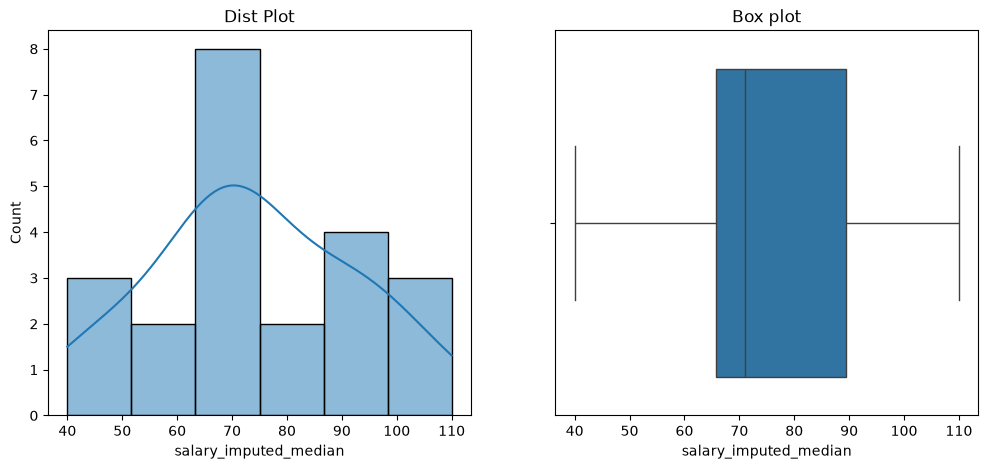

In [33]:
# imputation with mean

plt.figure(figsize = (12,5))
plt.subplot(1,2,1)
sns.histplot(df['salary_imputed_median'],kde = True)
plt.title("Dist Plot")


plt.subplot(1,2,2)
sns.boxplot(data=df,x = 'salary_imputed_median')
plt.title("Box plot")
plt.show

In [34]:
df

,salary,salary_imputed_mean,salary_imputed_median
0,11,74.318182,71.0
1,40,40.000000,40.0
2,45,45.000000,45.0
3,68,68.000000,68.0
4,65,65.000000,65.0
5,68,68.000000,68.0
6,78,78.000000,78.0
7,90,90.000000,90.0
8,57,57.000000,57.0
9,74,74.000000,74.0


## Capping the outliers >> replacing the nearest value which is not outlier

In [35]:

df

,salary,salary_imputed_mean,salary_imputed_median
0,11,74.318182,71.0
1,40,40.000000,40.0
2,45,45.000000,45.0
3,68,68.000000,68.0
4,65,65.000000,65.0
5,68,68.000000,68.0
6,78,78.000000,78.0
7,90,90.000000,90.0
8,57,57.000000,57.0
9,74,74.000000,74.0


In [40]:
lower_cap = df['salary'].quantile(0.05) # lower cao is 5th percentile
upper_cap = df['salary'].quantile(0.95) # upper cap as 95th percentile 

In [41]:
lower_cap

np.float64(40.25)

In [42]:
upper_cap

np.float64(109.55)

In [44]:
# replace outliers with cap
# where(condition,[x,y],/)
# Return elements chosen from 'x' or 'y' depending on 'condition'.
# if df['salary'] < lower_cap satisfied then lowwer_cap and df['salary'] >upper_cap satisfied than upper_cap
# otherwise keep salary as  it is

df['salary_capped'] = np.where(df['salary'] < lower_cap,lower_cap,
        np.where(df['salary']>upper_cap, upper_cap,df['salary']))

In [45]:
df

,salary,salary_imputed_mean,salary_imputed_median,salary_capped
0,11,74.318182,71.0,40.25
1,40,40.000000,40.0,40.25
2,45,45.000000,45.0,45.00
3,68,68.000000,68.0,68.00
4,65,65.000000,65.0,65.00
5,68,68.000000,68.0,68.00
6,78,78.000000,78.0,78.00
7,90,90.000000,90.0,90.00
8,57,57.000000,57.0,57.00
9,74,74.000000,74.0,74.00


<function matplotlib.pyplot.show(close=None, block=None)>

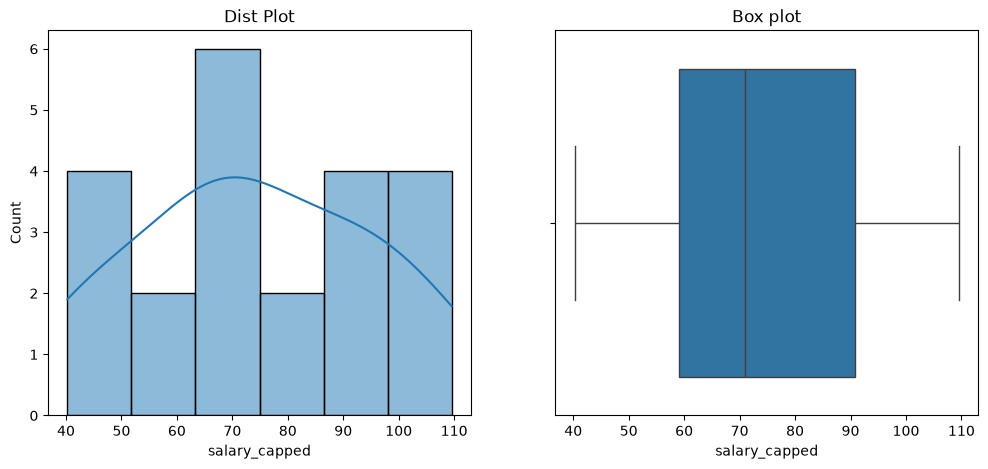

In [46]:
# imputation with capping

plt.figure(figsize = (12,5))
plt.subplot(1,2,1)
sns.histplot(df['salary_capped'],kde = True)
plt.title("Dist Plot")


plt.subplot(1,2,2)
sns.boxplot(data=df,x = 'salary_capped')
plt.title("Box plot")
plt.show

In [47]:
salary

[11,
 40,
 45,
 68,
 65,
 68,
 78,
 90,
 57,
 74,
 91,
 92,
 88,
 68,
 57,
 48,
 99,
 101,
 68,
 77,
 110,
 140]